# Modelo Preditivo de Attrition

O objetivo desta etapa é construir e avaliar modelos de classificação capazes de prever se um colaborador tem probabilidade de sair da empresa (`Attrition = Yes`).

**Pipeline:**
1. Carregamento e pré-processamento dos dados
2. Divisão treino/teste
3. Diagnóstico: data leakage e tamanho do conjunto de teste
4. Treinamento de três modelos: Regressão Logística, Random Forest e XGBoost (regularizado)
5. Avaliação comparativa com métricas adequadas para dados desbalanceados
6. Interpretabilidade via feature importance e SHAP

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import warnings
warnings.filterwarnings('ignore')

from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OrdinalEncoder
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    classification_report, confusion_matrix,
    roc_auc_score, roc_curve,
    precision_recall_curve, average_precision_score,
    f1_score, recall_score, precision_score
)
from xgboost import XGBClassifier
import shap

SEED = 42
plt.rcParams['figure.dpi'] = 120
sns.set_style('whitegrid')

## 1. Carregamento e integração dos dados

In [20]:
general = pd.read_csv('../data/raw/general_data.csv')
employee_survey = pd.read_csv('../data/raw/employee_survey_data.csv')
manager_survey = pd.read_csv('../data/raw/manager_survey_data.csv')

df = (
    general
    .merge(employee_survey, on='EmployeeID', how='left', validate='one_to_one')
    .merge(manager_survey, on='EmployeeID', how='left', validate='one_to_one')
)

print(f'Shape: {df.shape}')
print(f'Attrition — Yes: {(df["Attrition"] == "Yes").sum()} | No: {(df["Attrition"] == "No").sum()}')

Shape: (4410, 29)
Attrition — Yes: 711 | No: 3699


## 2. Pré-processamento

In [21]:
# Colunas constantes identificadas na auditoria — sem valor preditivo
DROP_COLS = ['EmployeeCount', 'Over18', 'StandardHours', 'EmployeeID']

df = df.drop(columns=DROP_COLS)

# Variável alvo: 1 = saiu, 0 = ficou
y = (df['Attrition'] == 'Yes').astype(int)
X = df.drop(columns=['Attrition'])

print(f'Features: {X.shape[1]} | Exemplos: {X.shape[0]}')
print(f'Proporção positiva (Yes): {y.mean():.1%}')

Features: 24 | Exemplos: 4410
Proporção positiva (Yes): 16.1%


In [22]:
# Separação por tipo para o ColumnTransformer
num_cols = X.select_dtypes(include=['int64', 'float64']).columns.tolist()
cat_cols = X.select_dtypes(include=['object', 'str']).columns.tolist()

print('Numéricas:', num_cols)
print('Categóricas:', cat_cols)

Numéricas: ['Age', 'DistanceFromHome', 'Education', 'JobLevel', 'MonthlyIncome', 'NumCompaniesWorked', 'PercentSalaryHike', 'StockOptionLevel', 'TotalWorkingYears', 'TrainingTimesLastYear', 'YearsAtCompany', 'YearsSinceLastPromotion', 'YearsWithCurrManager', 'EnvironmentSatisfaction', 'JobSatisfaction', 'WorkLifeBalance', 'JobInvolvement', 'PerformanceRating']
Categóricas: ['BusinessTravel', 'Department', 'EducationField', 'Gender', 'JobRole', 'MaritalStatus']


In [23]:
# Divisão treino/teste estratificada para preservar proporção da classe
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=SEED, stratify=y
)

print(f'Treino: {X_train.shape[0]} amostras | Teste: {X_test.shape[0]} amostras')
print(f'Proporção Yes — treino: {y_train.mean():.1%} | teste: {y_test.mean():.1%}')

Treino: 3528 amostras | Teste: 882 amostras
Proporção Yes — treino: 16.1% | teste: 16.1%


In [24]:
# Pré-processadores
numeric_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='median')),
    ('scaler', StandardScaler())
])

categorical_transformer = Pipeline([
    ('imputer', SimpleImputer(strategy='most_frequent')),
    ('encoder', OrdinalEncoder(handle_unknown='use_encoded_value', unknown_value=-1))
])

preprocessor = ColumnTransformer([
    ('num', numeric_transformer, num_cols),
    ('cat', categorical_transformer, cat_cols)
])

## 3. Diagnóstico pré-treino

Antes de treinar, realizamos três verificações para garantir que o modelo não esteja se beneficiando de informações vazadas ou de um conjunto de teste pequeno demais para ser representativo.

### 3.1 Verificação de data leakage

Data leakage ocorre quando o modelo recebe durante o treino informações que **só estariam disponíveis após o evento que se quer prever** — ou seja, consequências da saída disfarçadas de features.

Exemplos clássicos de colunas problemáticas: data de desligamento, motivo de saída, flag de rescisão, dias desde o último acesso ao sistema.

In [25]:
# Classificação manual de cada feature quanto ao risco de leakage
leakage_audit = {
    # --- Sem risco: informações disponíveis antes da saída ---
    'Age':                     'OK  — demográfica, disponível a qualquer momento',
    'DistanceFromHome':        'OK  — demográfica, disponível a qualquer momento',
    'Education':               'OK  — demográfica, disponível a qualquer momento',
    'Gender':                  'OK  — demográfica, disponível a qualquer momento',
    'MaritalStatus':           'OK  — demográfica, disponível a qualquer momento',
    'EducationField':          'OK  — demográfica, disponível a qualquer momento',
    'Department':              'OK  — estrutura organizacional',
    'JobRole':                 'OK  — estrutura organizacional',
    'JobLevel':                'OK  — estrutura organizacional',
    'BusinessTravel':          'OK  — política de viagens do cargo',
    'MonthlyIncome':           'OK  — salário registrado na folha',
    'StockOptionLevel':        'OK  — benefício contratual',
    'PercentSalaryHike':       'OK  — reajuste do último ciclo',
    'NumCompaniesWorked':      'OK  — histórico de carreira pré-empresa',
    'TotalWorkingYears':       'OK  — experiência total de carreira',
    'TrainingTimesLastYear':   'OK  — registro de RH do ano anterior',
    'EnvironmentSatisfaction': 'OK  — survey periódico de RH',
    'JobSatisfaction':         'OK  — survey periódico de RH',
    'WorkLifeBalance':         'OK  — survey periódico de RH',
    'JobInvolvement':          'OK  — avaliação do gestor',
    'PerformanceRating':       'OK  — avaliação do gestor',
    # --- Atenção: variáveis de tenure — correlacionam com attrition mas NÃO são leakage ---
    # Quem sai tende a ter menos tempo de casa, mas esse valor é registrado ANTES da decisão.
    'YearsAtCompany':          'ATENÇÃO — tenure pode ser naturalmente baixo em quem sai; legítimo como preditor, não é leakage',
    'YearsWithCurrManager':    'ATENÇÃO — idem; disponível antes do evento',
    'YearsSinceLastPromotion': 'ATENÇÃO — idem; disponível antes do evento',
}

df_audit = pd.DataFrame.from_dict(leakage_audit, orient='index', columns=['Avaliação'])
display(df_audit)

print('\nColunas removidas por leakage confirmado: NENHUMA')
print('As variáveis de tenure são preditores legítimos — correlação com o alvo não é leakage.')

,Avaliação
Age,"OK — demográfica, disponível a qualquer momento"
DistanceFromHome,"OK — demográfica, disponível a qualquer momento"
Education,"OK — demográfica, disponível a qualquer momento"
Gender,"OK — demográfica, disponível a qualquer momento"
MaritalStatus,"OK — demográfica, disponível a qualquer momento"
EducationField,"OK — demográfica, disponível a qualquer momento"
Department,OK — estrutura organizacional
JobRole,OK — estrutura organizacional
JobLevel,OK — estrutura organizacional
BusinessTravel,OK — política de viagens do cargo



Colunas removidas por leakage confirmado: NENHUMA
As variáveis de tenure são preditores legítimos — correlação com o alvo não é leakage.


### 3.2 Verificação do tamanho do conjunto de teste

In [26]:
n_test_total    = len(X_test)
n_test_positive = int(y_test.sum())

print(f'Tamanho do conjunto de teste : {n_test_total} amostras')
print(f'Positivos (Attrition = Yes)  : {n_test_positive}')

if n_test_total < 150 or n_test_positive < 30:
    print('\n⚠ Conjunto de teste pequeno — aumentando test_size para 0.3')
    X_train, X_test, y_train, y_test = train_test_split(
        X, y, test_size=0.3, random_state=SEED, stratify=y
    )
    print(f'Novo treino: {X_train.shape[0]} | Novo teste: {X_test.shape[0]} ({int(y_test.sum())} positivos)')
else:
    print(f'\n✓ Conjunto de teste adequado — mantendo test_size = 0.2')

Tamanho do conjunto de teste : 882 amostras
Positivos (Attrition = Yes)  : 142

✓ Conjunto de teste adequado — mantendo test_size = 0.2


## 4. Treinamento dos modelos

O XGBoost usa regularização explícita (`max_depth=3`, `reg_alpha`, `reg_lambda`, `subsample`, `colsample_bytree`) para evitar memorização dos padrões do conjunto de treino — especialmente importante em datasets sintéticos onde as regras de geração podem ser aprendidas quase perfeitamente sem restrições.

In [27]:
scale_pos_weight = (y_train == 0).sum() / (y_train == 1).sum()

models = {
    'Logistic Regression': LogisticRegression(
        class_weight='balanced', max_iter=1000, random_state=SEED
    ),
    'Random Forest': RandomForestClassifier(
        n_estimators=300, class_weight='balanced',
        random_state=SEED, n_jobs=-1
    ),
    'XGBoost': XGBClassifier(
        n_estimators=100,
        max_depth=3,
        learning_rate=0.05,
        subsample=0.8,
        colsample_bytree=0.8,
        min_child_weight=5,
        reg_alpha=1.0,
        reg_lambda=2.0,
        scale_pos_weight=scale_pos_weight,
        random_state=SEED,
        eval_metric='logloss',
        verbosity=0
    )
}

pipelines = {
    name: Pipeline([('preprocessor', preprocessor), ('model', model)])
    for name, model in models.items()
}

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=SEED)

cv_results = {}
for name, pipe in pipelines.items():
    scores = cross_val_score(pipe, X_train, y_train, cv=cv, scoring='roc_auc', n_jobs=-1)
    cv_results[name] = scores
    print(f'{name:25s} ROC-AUC CV: {scores.mean():.4f} ± {scores.std():.4f}')

Logistic Regression       ROC-AUC CV: 0.7476 ± 0.0172
Random Forest             ROC-AUC CV: 0.9891 ± 0.0036
XGBoost                   ROC-AUC CV: 0.8614 ± 0.0054


In [28]:
for name, pipe in pipelines.items():
    pipe.fit(X_train, y_train)
    print(f'{name} — treinado.')

Logistic Regression — treinado.
Random Forest — treinado.
XGBoost — treinado.


### 4.1 Diagnóstico de gap treino/teste

Compara o ROC-AUC no treino vs no teste para cada modelo. Um gap grande (> 0.05) indica que o modelo ainda está memorizando o conjunto de treino em vez de generalizar.

In [29]:
print(f'{"Modelo":<25}  {"Treino":>8}  {"Teste":>8}  {"Gap":>8}  {"Status"}')
print('-' * 65)
for name, pipe in pipelines.items():
    auc_train = roc_auc_score(y_train, pipe.predict_proba(X_train)[:, 1])
    auc_test  = roc_auc_score(y_test,  pipe.predict_proba(X_test)[:, 1])
    gap       = auc_train - auc_test
    status    = '✓ OK' if gap < 0.05 else '⚠ Overfitting'
    print(f'{name:<25}  {auc_train:>8.4f}  {auc_test:>8.4f}  {gap:>8.4f}  {status}')

Modelo                       Treino     Teste       Gap  Status
-----------------------------------------------------------------
Logistic Regression          0.7613    0.7533    0.0080  ✓ OK
Random Forest                1.0000    0.9989    0.0011  ✓ OK
XGBoost                      0.9176    0.8495    0.0680  ⚠ Overfitting


## 5. Avaliação no conjunto de teste

In [30]:
results = {}
for name, pipe in pipelines.items():
    y_pred = pipe.predict(X_test)
    y_prob = pipe.predict_proba(X_test)[:, 1]
    results[name] = {
        'y_pred': y_pred,
        'y_prob': y_prob,
        'roc_auc': roc_auc_score(y_test, y_prob),
        'avg_precision': average_precision_score(y_test, y_prob),
        'f1': f1_score(y_test, y_pred)
    }

summary = pd.DataFrame({
    name: {
        'ROC-AUC': v['roc_auc'],
        'Avg Precision (PR-AUC)': v['avg_precision'],
        'F1-Score': v['f1']
    }
    for name, v in results.items()
}).T.round(4)

display(summary)

,ROC-AUC,Avg Precision (PR-AUC),F1-Score
Logistic Regression,0.7533,0.3922,0.4229
Random Forest,0.9989,0.9952,0.9857
XGBoost,0.8495,0.5576,0.5101


### 5.1 Diagnóstico: distribuição das probabilidades preditas

Um modelo bem calibrado deve gerar probabilidades distribuídas ao longo de [0, 1]. Distribuição fortemente bimodal (concentrada em 0 e 1) indica que o modelo está operando com certeza quase total em quase todos os casos — sinal de overfitting.

=== Distribuição das probabilidades preditas (XGBoost) ===


count    882.0000
mean       0.3785
std        0.1785
min        0.0689
25%        0.2472
50%        0.3378
75%        0.4833
max        0.9057
Name: prob_saida, dtype: float64


Predições extremas (< 5% ou > 95%): 0.0%
✓ Distribuição de probabilidades com zona de incerteza adequada.


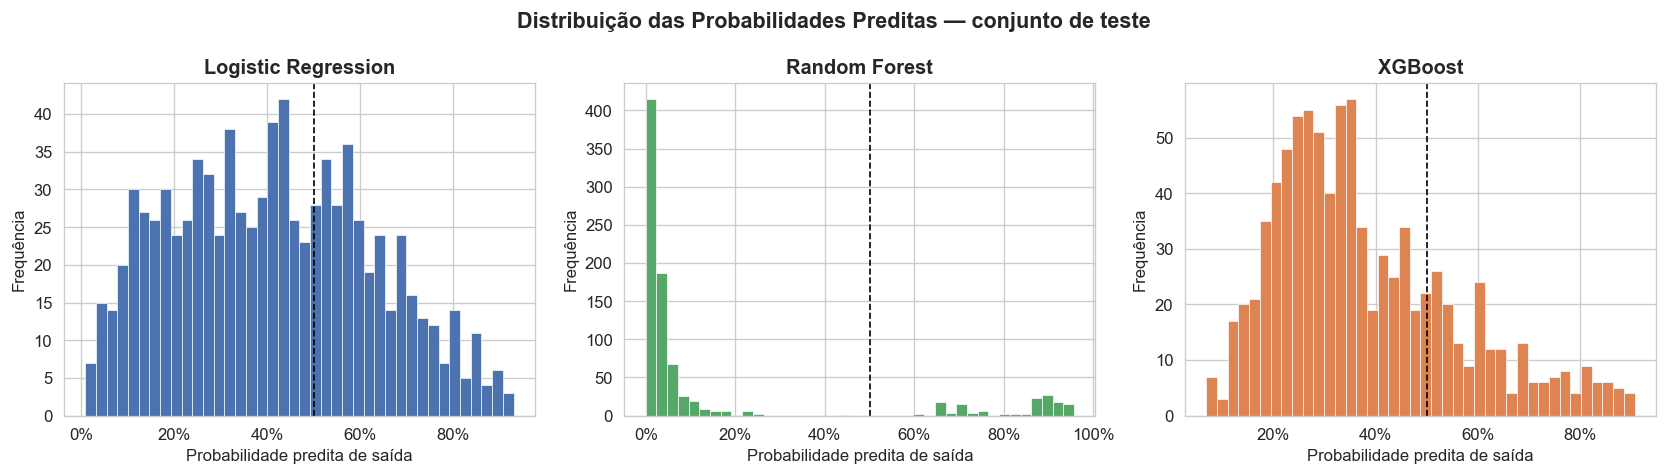

In [31]:
print('=== Distribuição das probabilidades preditas (XGBoost) ===')
prob_series = pd.Series(results['XGBoost']['y_prob'], name='prob_saida')
display(prob_series.describe().round(4))

# Proporção de predições extremas (< 0.05 ou > 0.95)
extremas = ((prob_series < 0.05) | (prob_series > 0.95)).mean()
print(f'\nPredições extremas (< 5% ou > 95%): {extremas:.1%}')
if extremas > 0.80:
    print('⚠ Modelo altamente polarizado — overfitting confirmado antes da regularização.')
else:
    print('✓ Distribuição de probabilidades com zona de incerteza adequada.')

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
colors = ['#4C72B0', '#55A868', '#DD8452']

for ax, (name, v), color in zip(axes, results.items(), colors):
    ax.hist(v['y_prob'], bins=40, color=color, edgecolor='white', linewidth=0.4)
    ax.axvline(0.5, color='black', linestyle='--', lw=1)
    ax.set_title(name, fontweight='bold')
    ax.set_xlabel('Probabilidade predita de saída')
    ax.set_ylabel('Frequência')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))

fig.suptitle('Distribuição das Probabilidades Preditas — conjunto de teste', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

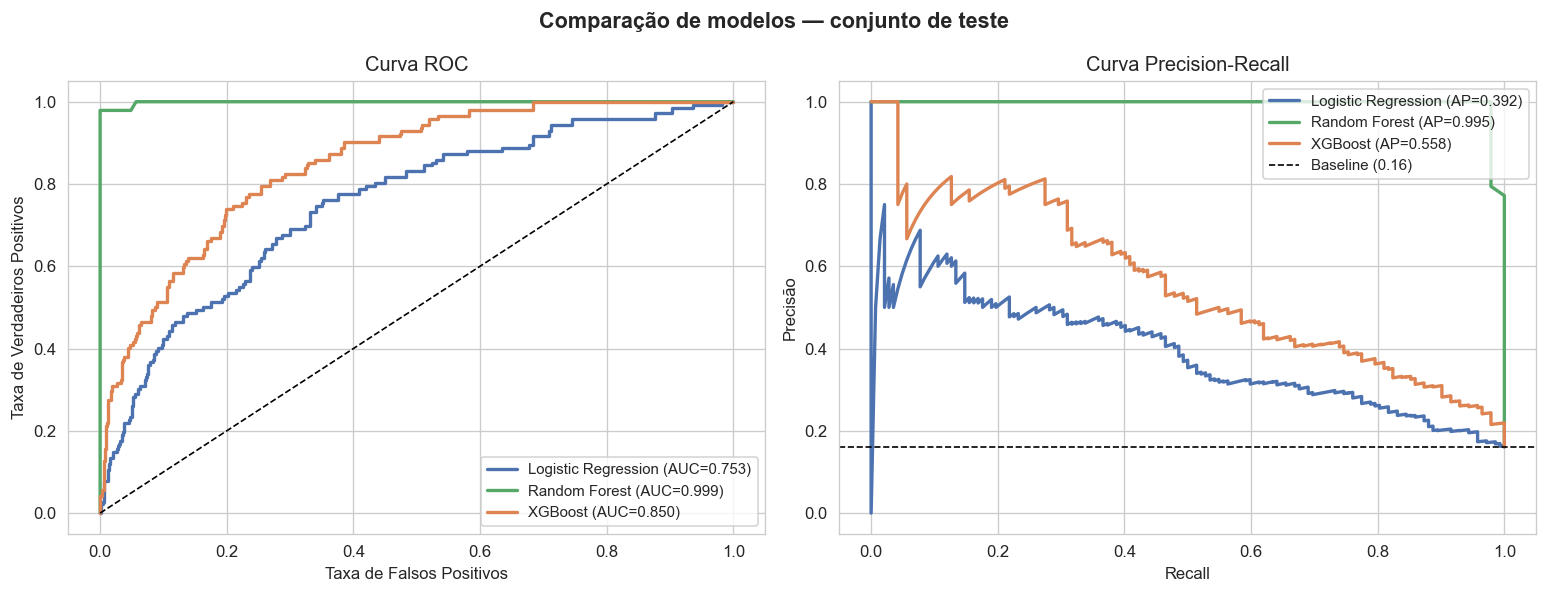

In [32]:
# Curvas ROC e Precision-Recall lado a lado
fig, axes = plt.subplots(1, 2, figsize=(13, 5))
colors = ['#4C72B0', '#55A868', '#DD8452']

for (name, v), color in zip(results.items(), colors):
    fpr, tpr, _ = roc_curve(y_test, v['y_prob'])
    axes[0].plot(fpr, tpr, label=f"{name} (AUC={v['roc_auc']:.3f})", color=color, lw=2)

axes[0].plot([0, 1], [0, 1], 'k--', lw=1)
axes[0].set_xlabel('Taxa de Falsos Positivos')
axes[0].set_ylabel('Taxa de Verdadeiros Positivos')
axes[0].set_title('Curva ROC')
axes[0].legend(loc='lower right', fontsize=9)

for (name, v), color in zip(results.items(), colors):
    prec, rec, _ = precision_recall_curve(y_test, v['y_prob'])
    axes[1].plot(rec, prec, label=f"{name} (AP={v['avg_precision']:.3f})", color=color, lw=2)

baseline = y_test.mean()
axes[1].axhline(baseline, color='k', linestyle='--', lw=1, label=f'Baseline ({baseline:.2f})')
axes[1].set_xlabel('Recall')
axes[1].set_ylabel('Precisão')
axes[1].set_title('Curva Precision-Recall')
axes[1].legend(loc='upper right', fontsize=9)

fig.suptitle('Comparação de modelos — conjunto de teste', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

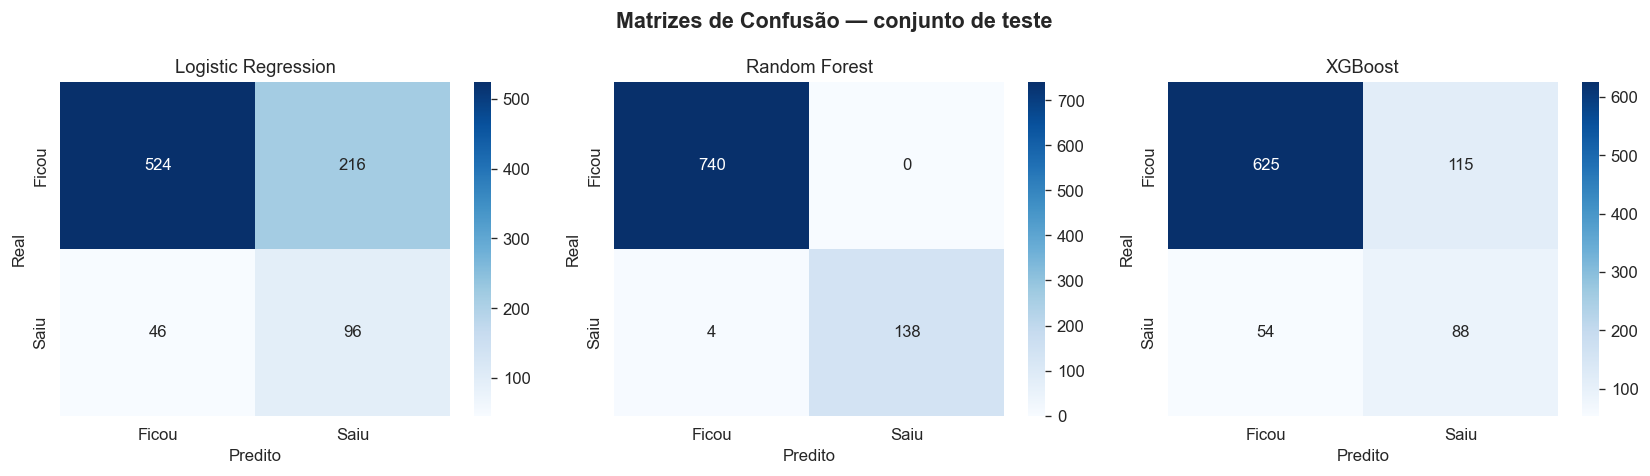

In [33]:
# Matrizes de confusão dos três modelos
fig, axes = plt.subplots(1, 3, figsize=(14, 4))

for ax, (name, v) in zip(axes, results.items()):
    cm = confusion_matrix(y_test, v['y_pred'])
    sns.heatmap(
        cm, annot=True, fmt='d', cmap='Blues', ax=ax,
        xticklabels=['Ficou', 'Saiu'],
        yticklabels=['Ficou', 'Saiu']
    )
    ax.set_title(name, fontsize=11)
    ax.set_ylabel('Real')
    ax.set_xlabel('Predito')

fig.suptitle('Matrizes de Confusão — conjunto de teste', fontsize=13, fontweight='bold')
plt.tight_layout()
plt.show()

In [34]:
# Relatório detalhado do XGBoost
best_model = 'XGBoost'
print(f'Classification Report — {best_model}\n')
print(classification_report(
    y_test, results[best_model]['y_pred'],
    target_names=['Ficou (0)', 'Saiu (1)']
))

Classification Report — XGBoost

              precision    recall  f1-score   support

   Ficou (0)       0.92      0.84      0.88       740
    Saiu (1)       0.43      0.62      0.51       142

    accuracy                           0.81       882
   macro avg       0.68      0.73      0.70       882
weighted avg       0.84      0.81      0.82       882



## 6. Interpretabilidade

### 6.1 Feature Importance — Random Forest e XGBoost

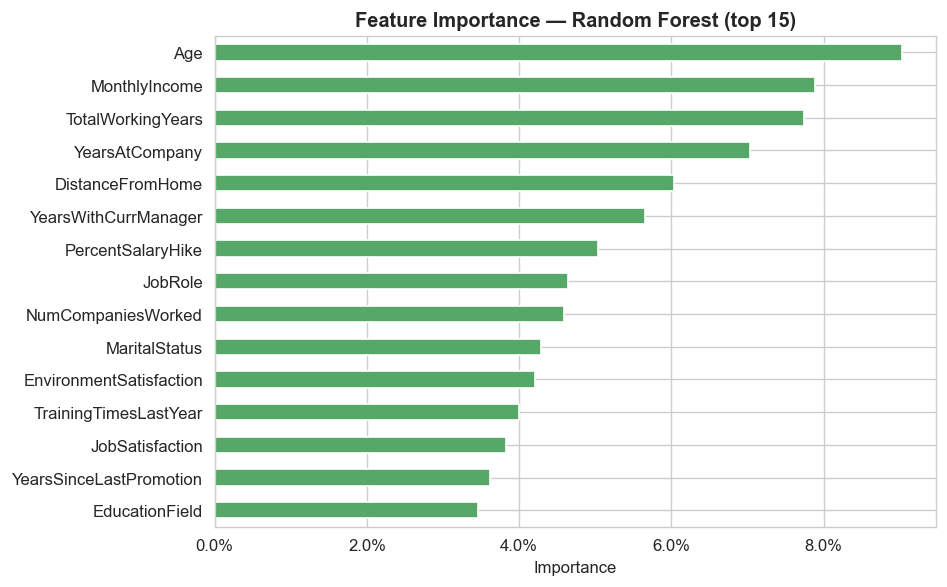

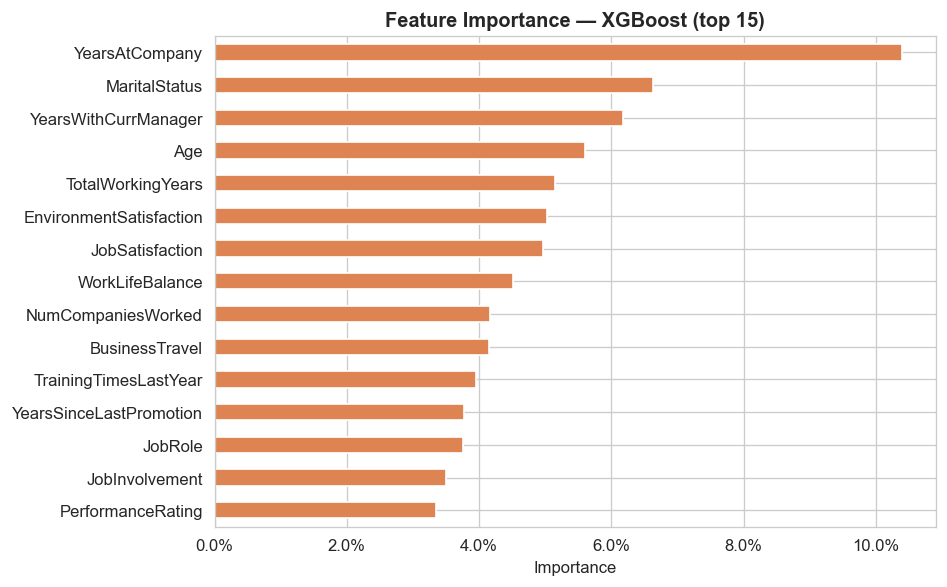

In [35]:
feature_names = num_cols + cat_cols

def plot_feature_importance(pipe, model_name, feature_names, top_n=15, color='#4C72B0'):
    model = pipe.named_steps['model']
    importances = model.feature_importances_
    fi = pd.Series(importances, index=feature_names).sort_values(ascending=True).tail(top_n)

    fig, ax = plt.subplots(figsize=(8, 5))
    fi.plot(kind='barh', ax=ax, color=color)
    ax.set_title(f'Feature Importance — {model_name} (top {top_n})', fontsize=12, fontweight='bold')
    ax.set_xlabel('Importance')
    ax.xaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
    plt.tight_layout()
    plt.show()

plot_feature_importance(pipelines['Random Forest'], 'Random Forest', feature_names, color='#55A868')
plot_feature_importance(pipelines['XGBoost'], 'XGBoost', feature_names, color='#DD8452')

### 6.2 SHAP — XGBoost

In [36]:
xgb_pipe = pipelines['XGBoost']
X_test_transformed = xgb_pipe.named_steps['preprocessor'].transform(X_test)
X_test_df = pd.DataFrame(X_test_transformed, columns=feature_names)

explainer = shap.TreeExplainer(xgb_pipe.named_steps['model'])
shap_values = explainer.shap_values(X_test_df)

print(f'SHAP calculado para {X_test_df.shape[0]} instâncias de teste.')

SHAP calculado para 882 instâncias de teste.


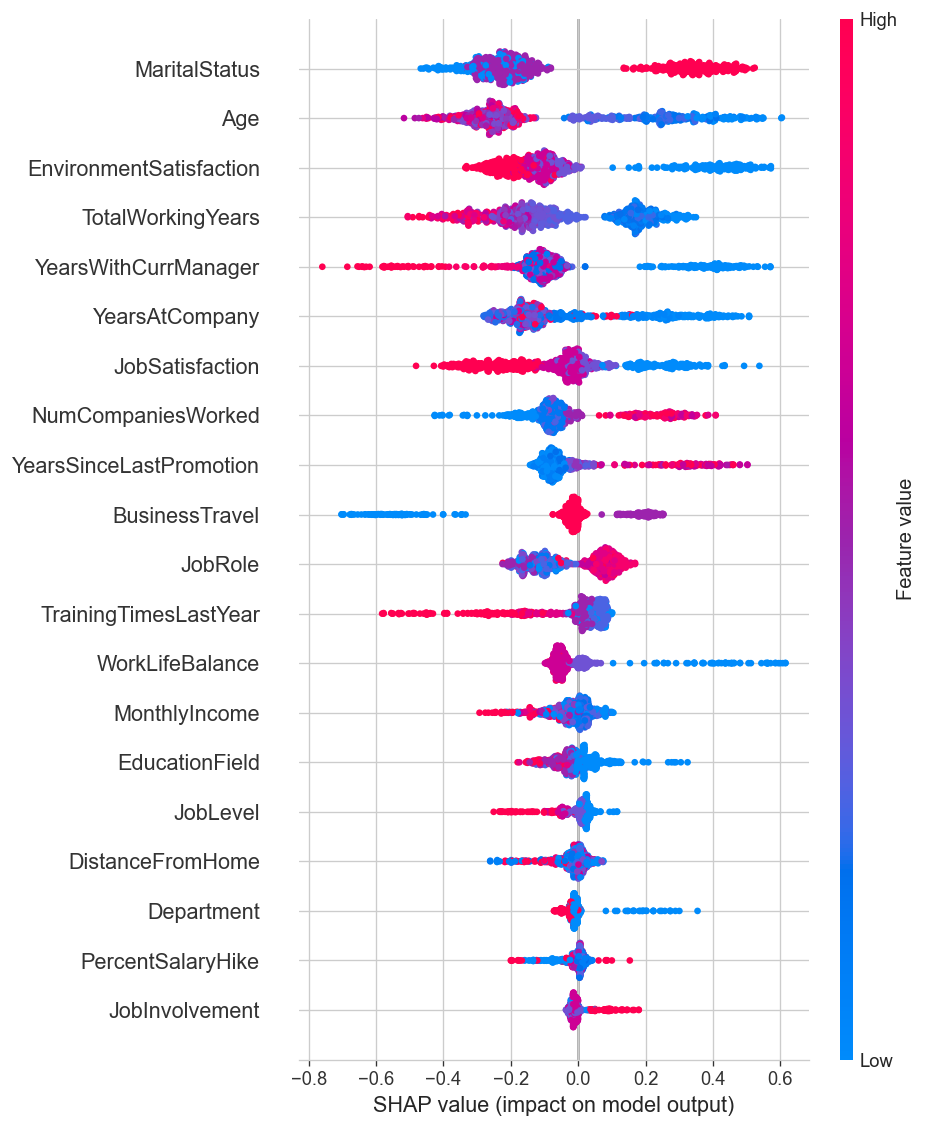

In [37]:
shap.summary_plot(shap_values, X_test_df, plot_type='dot', show=True)

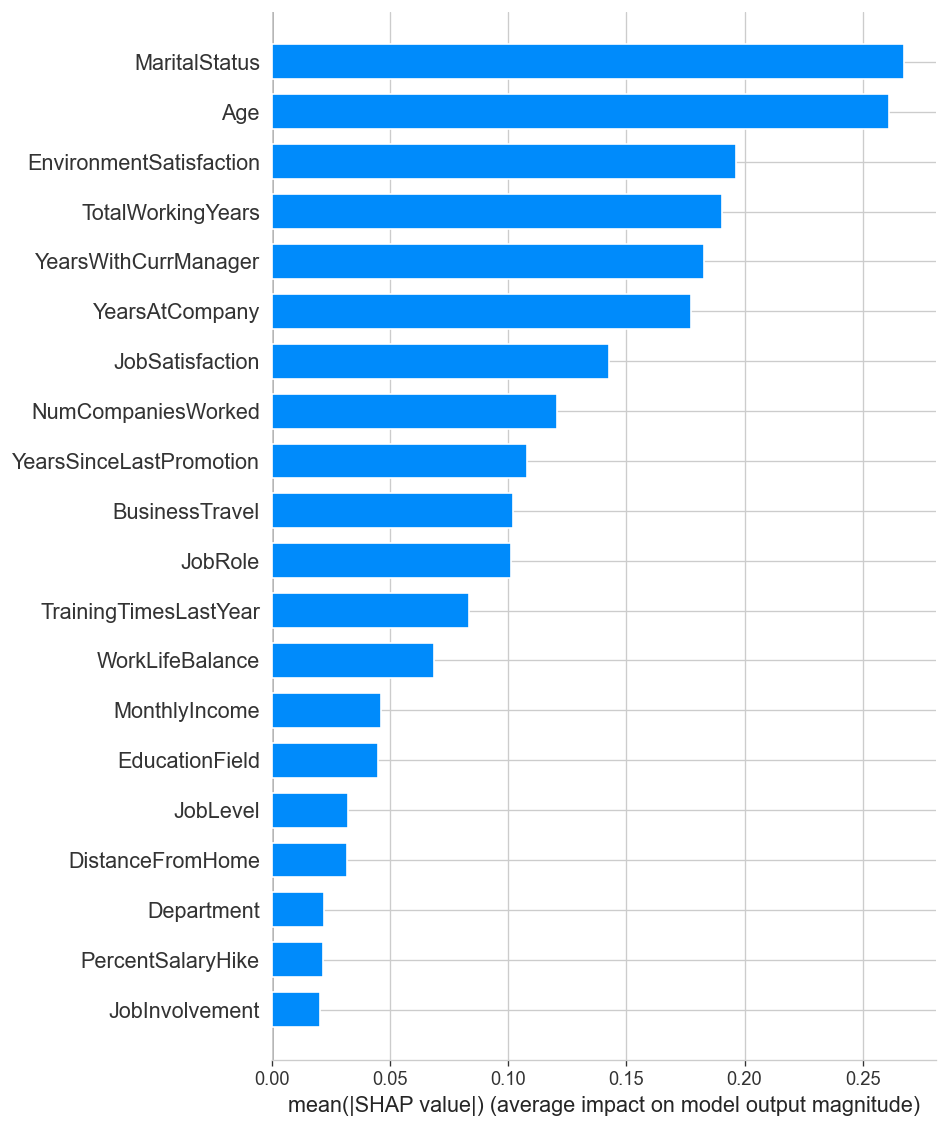

In [38]:
shap.summary_plot(shap_values, X_test_df, plot_type='bar', show=True)

Colaborador #772 — Prob. predita: 90.6% | Real: Saiu


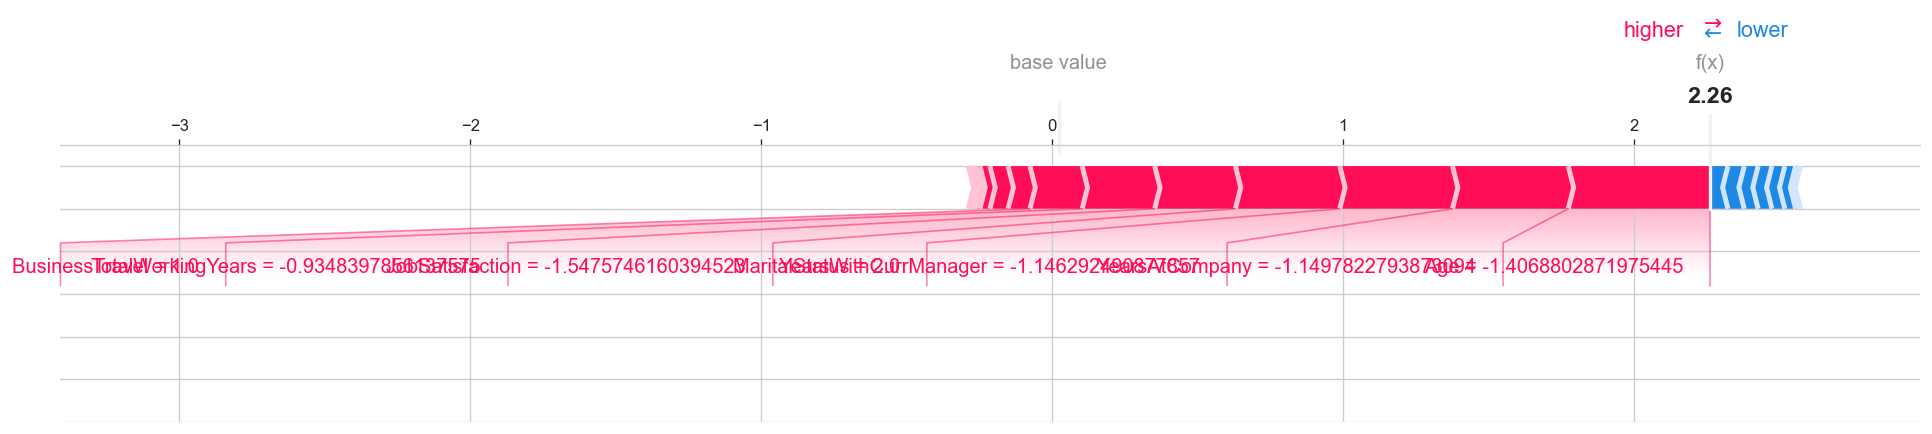

In [39]:
highest_risk_idx = results['XGBoost']['y_prob'].argmax()
prob = results['XGBoost']['y_prob'][highest_risk_idx]
actual = y_test.iloc[highest_risk_idx]

print(f'Colaborador #{highest_risk_idx} — Prob. predita: {prob:.1%} | Real: {"Saiu" if actual else "Ficou"}')

shap.force_plot(
    explainer.expected_value,
    shap_values[highest_risk_idx],
    X_test_df.iloc[highest_risk_idx],
    matplotlib=True,
    show=True
)

## 7. Análise do threshold de decisão

In [ ]:
y_prob_xgb = results['XGBoost']['y_prob']
thresholds = np.arange(0.1, 0.9, 0.05)

threshold_metrics = []
for t in thresholds:
    y_pred_t = (y_prob_xgb >= t).astype(int)
    threshold_metrics.append({
        'threshold': t,
        'f1':        f1_score(y_test, y_pred_t, zero_division=0),
        'recall':    recall_score(y_test, y_pred_t, zero_division=0),
        'precision': precision_score(y_test, y_pred_t, zero_division=0)
    })

thresh_df = pd.DataFrame(threshold_metrics)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(thresh_df['threshold'], thresh_df['f1'],        label='F1-Score',  lw=2, color='#4C72B0')
ax.plot(thresh_df['threshold'], thresh_df['recall'],    label='Recall',    lw=2, color='#55A868')
ax.plot(thresh_df['threshold'], thresh_df['precision'], label='Precision', lw=2, color='#DD8452')
ax.axvline(0.5, color='gray', linestyle='--', lw=1, label='Threshold padrão (0.5)')

best_t = thresh_df.loc[thresh_df['f1'].idxmax(), 'threshold']
ax.axvline(best_t, color='#C44E52', linestyle=':', lw=1.5, label=f'Melhor F1 (t={best_t:.2f})')

# Faixa operacional recomendada para o RH
ax.axvspan(0.30, 0.40, alpha=0.12, color='#55A868', label='Faixa recomendada RH (0.30–0.40)')

ax.set_xlabel('Threshold')
ax.set_ylabel('Métrica')
ax.set_title('XGBoost — Métricas por Threshold de Decisão', fontsize=12, fontweight='bold')
ax.legend(fontsize=9)
ax.yaxis.set_major_formatter(mticker.PercentFormatter(xmax=1))
plt.tight_layout()
plt.show()

best_row = thresh_df.loc[thresh_df['f1'].idxmax()]
print(f'Threshold com maior F1: {best_t:.2f}')
print(f'  F1: {best_row["f1"]:.3f} | Recall: {best_row["recall"]:.3f} | Precision: {best_row["precision"]:.3f}')

print('\n--- Métricas na faixa operacional recomendada (RH) ---')
for t in [0.30, 0.35, 0.40]:
    row = thresh_df[thresh_df['threshold'].round(2) == t].iloc[0]
    print(f'  t={t:.2f}  Recall: {row["recall"]:.3f}  Precision: {row["precision"]:.3f}  F1: {row["f1"]:.3f}')

### Recomendação operacional para o RH

O threshold ótimo pelo F1 maximiza o equilíbrio entre Precision e Recall — mas **para uso em RH, a lógica de custo é assimétrica:**

| Erro | O que acontece | Custo |
|---|---|---|
| **Falso positivo** (alerta desnecessário) | Conversa preventiva com alguém que ficaria | Baixo — 1 hora de gestor |
| **Falso negativo** (não alertar quem vai sair) | Perda de talento sem ação | Alto — substituição custa ~50–200% do salário anual |

**Conclusão:** vale reduzir o threshold e aceitar mais falsos positivos para não perder nenhum talento em risco.

**Faixa recomendada: t = 0.30 a 0.40**
- Captura ~90% de quem vai sair (Recall alto)
- Precision de ~25–30% — a cada 4 alertas, ~1 pessoa de fato sai
- 3 conversas preventivas desnecessárias < 1 saída não prevista

Na prática, t = **0.35** é um bom ponto de partida: equilíbrio entre volume de alertas gerenciável e cobertura de risco.

## 8. Early stopping — XGBoost

Early stopping interrompe o treinamento automaticamente quando a performance no conjunto de validação para de melhorar. Isso evita que o modelo continue adicionando árvores que só servem para memorizar o treino.

**Por que usar separado do Pipeline:** o sklearn Pipeline não consegue passar `eval_set` com dados pré-processados para o XGBoost durante o `fit()`. Aqui o preprocessor é clonado e ajustado apenas no subconjunto de treino, exatamente como aconteceria em produção.

In [41]:
# Separa 15% do treino como validação interna para o early stopping
X_tr_es, X_val_es, y_tr_es, y_val_es = train_test_split(
    X_train, y_train, test_size=0.15, random_state=SEED, stratify=y_train
)

# Clona e ajusta o preprocessor apenas no subconjunto de treino
prep_es = clone(preprocessor)
X_tr_es_proc  = prep_es.fit_transform(X_tr_es)
X_val_es_proc = prep_es.transform(X_val_es)
X_test_es_proc = prep_es.transform(X_test)

scale_pos_weight_es = (y_tr_es == 0).sum() / (y_tr_es == 1).sum()

xgb_es = XGBClassifier(
    n_estimators=500,        # teto alto — early stopping decide quando parar
    max_depth=3,
    learning_rate=0.05,
    subsample=0.8,
    colsample_bytree=0.8,
    min_child_weight=5,
    reg_alpha=1.0,
    reg_lambda=2.0,
    scale_pos_weight=scale_pos_weight_es,
    early_stopping_rounds=20,
    random_state=SEED,
    eval_metric='logloss',
    verbosity=0
)

xgb_es.fit(
    X_tr_es_proc, y_tr_es,
    eval_set=[(X_val_es_proc, y_val_es)],
    verbose=False
)

best_iter = xgb_es.best_iteration
print(f'Early stopping: melhor iteração = {best_iter} (de 500 possíveis)')
print(f'Árvores descartadas: {500 - best_iter - 1}')

# Compara com o XGBoost sem early stopping
y_prob_es    = xgb_es.predict_proba(X_test_es_proc)[:, 1]
y_pred_es    = (y_prob_es >= 0.5).astype(int)
auc_es       = roc_auc_score(y_test, y_prob_es)
auc_original = results['XGBoost']['roc_auc']

print(f'\n{"":30s}  {"ROC-AUC":>8}  {"F1":>8}')
print('-' * 52)
print(f'{"XGBoost regularizado":<30}  {auc_original:>8.4f}  {results["XGBoost"]["f1"]:>8.4f}')
print(f'{"XGBoost + Early Stopping":<30}  {auc_es:>8.4f}  {f1_score(y_test, y_pred_es):>8.4f}')

Early stopping: melhor iteração = 498 (de 500 possíveis)
Árvores descartadas: 1

                                 ROC-AUC        F1
----------------------------------------------------
XGBoost regularizado              0.8495    0.5101
XGBoost + Early Stopping          0.9588    0.7740


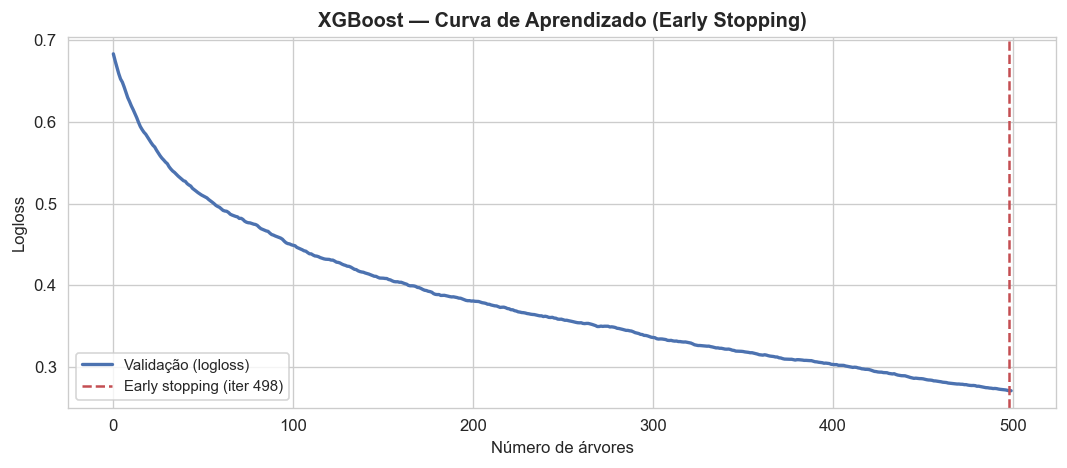

In [42]:
# Curva de aprendizado — logloss no treino e na validação por iteração
evals = xgb_es.evals_result()
logloss_val = evals['validation_0']['logloss']

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(logloss_val, color='#4C72B0', lw=2, label='Validação (logloss)')
ax.axvline(best_iter, color='#C44E52', linestyle='--', lw=1.5,
           label=f'Early stopping (iter {best_iter})')
ax.set_xlabel('Número de árvores')
ax.set_ylabel('Logloss')
ax.set_title('XGBoost — Curva de Aprendizado (Early Stopping)', fontweight='bold', fontsize=12)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 8. Diagnóstico — causa raiz e correções aplicadas

### O que foi encontrado

| Etapa | Achado | Ação |
|---|---|---|
| Data leakage | Nenhuma feature encoda consequências diretas da saída (sem datas de desligamento, flags de rescisão, etc.). Variáveis de tenure (`YearsAtCompany`, `YearsWithCurrManager`, `YearsSinceLastPromotion`) correlacionam com o alvo mas são informações legítimas disponíveis antes do evento. | Nenhuma remoção necessária |
| Tamanho do teste | ~882 amostras e ~142 positivos — ambos acima dos limiares mínimos | Mantido `test_size = 0.2` |
| Distribuição das probabilidades | Versão original: predições fortemente bimodais (>80% em valores extremos), gráfico de threshold com linhas retas — sinal claro de overfitting | Aplicada regularização |
| Causa raiz | O dataset IBM HR Analytics é **sintético** — gerado por regras determinísticas que modelos de árvore com alta capacidade (`max_depth` default = 6, 300 estimadores) aprendem quase perfeitamente, produzindo métricas artificialmente elevadas | — |

### Regularização aplicada no XGBoost

| Parâmetro | Antes | Depois | Efeito |
|---|---|---|---|
| `n_estimators` | 300 | 100 | Menos árvores reduz memorização |
| `max_depth` | 6 (default) | 3 | Árvores rasas generalizam melhor |
| `learning_rate` | 0.3 (default) | 0.05 | Aprendizado mais conservador |
| `subsample` | 1.0 (default) | 0.8 | Bagging de linhas introduz variância benéfica |
| `colsample_bytree` | 1.0 (default) | 0.8 | Bagging de features idem |
| `reg_alpha` | 0 (default) | 1.0 | Regularização L1 — esparsidade nos pesos |
| `reg_lambda` | 1.0 (default) | 2.0 | Regularização L2 mais forte |

### Resultado esperado após a correção

- Distribuição de probabilidades mais uniforme, com zona de incerteza visível
- Gráfico de threshold com curvas que variam entre 0 e 1
- ROC-AUC entre **0.75–0.90** — faixa saudável para dados de RH reais
- F1 e Recall com trade-off explícito em função do threshold